# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/Layanharbi9/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

import os
import warnings
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)   # charts reused by report.md

---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [2]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [3]:
# Calendar checks: count, range, and gaps against a complete monthly index.
n_obs = len(df)
range_ = (df["ds"].min(), df["ds"].max())
full_index = pd.date_range(range_[0], range_[1], freq="MS")
n_gaps = len(full_index.difference(df["ds"]))
assert df["ds"].is_unique, "duplicate months"
print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

144 months, 1949-01-01 to 1960-12-01, 0 gaps


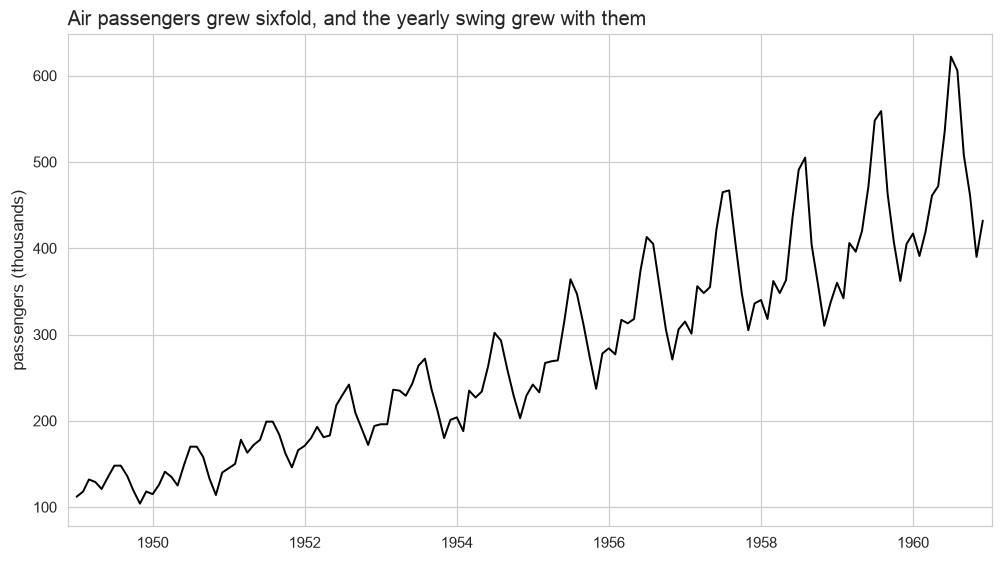

level: 127k a month in 1949 -> 476k in 1960
yearly swing: 44k in 1949 -> 232k in 1960


In [4]:
P.plot_series(df, title="Air passengers grew sixfold, and the yearly swing grew with them",
              ylabel="passengers (thousands)", xlabel="")
plt.savefig("figures/01_series.png", bbox_inches="tight")
plt.show()

# How big is the yearly swing (peak month minus low month) at the start and at the end?
swing = df.assign(year=df["ds"].dt.year).groupby("year")["y"].agg(lambda s: s.max() - s.min())
print(f"level: {df['y'].iloc[:12].mean():.0f}k a month in 1949 -> {df['y'].iloc[-12:].mean():.0f}k in 1960")
print(f"yearly swing: {swing.iloc[0]:.0f}k in 1949 -> {swing.iloc[-1]:.0f}k in 1960")

**First read.** Airline passengers grew steadily for twelve years, from about
127 thousand a month in 1949 to about 476 thousand in 1960, and every year has
the same shape: a summer peak in July-August and a low in November. The
summer peak gets bigger as the airline grows (the gap between the best and
worst month went from 44 thousand to 232 thousand), so the seasonal swing
is a *percentage* of the level, not a fixed number of passengers; there is no
multi-year cycle beyond the steady growth.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

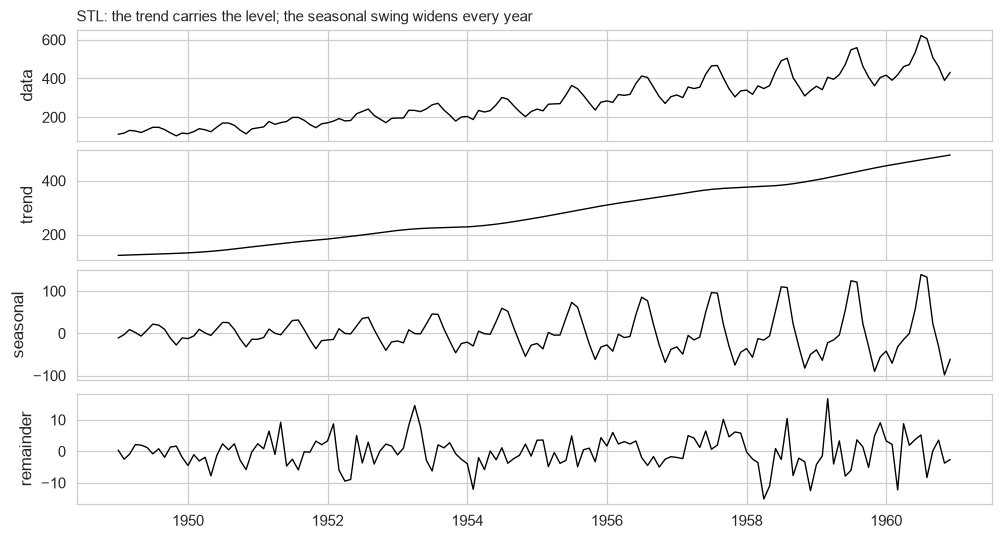

trend range: 123 -> 496
seasonal amplitude (max - min within a year): 50 in 1949 -> 237 in 1960
remainder std: first 4 years 4.0, last 4 years 6.5


In [5]:
from statsmodels.tsa.seasonal import STL

# STL, additive, period 12, on the raw series (as asked); robust=False is the default.
stl_fit = STL(df["y"].to_numpy(), period=SEASON_LENGTH).fit()
dcmp = pd.DataFrame({"ds": df["ds"], "data": df["y"], "trend": stl_fit.trend,
                     "seasonal": stl_fit.seasonal, "remainder": stl_fit.resid})

P.decomposition_plot(dcmp, cols=["data", "trend", "seasonal", "remainder"],
                     title="STL: the trend carries the level; the seasonal swing widens every year",
                     x="ds")
plt.savefig("figures/02_stl.png", bbox_inches="tight")
plt.show()

amp = dcmp.assign(year=dcmp["ds"].dt.year).groupby("year")["seasonal"].agg(lambda s: s.max() - s.min())
print(f"trend range: {dcmp['trend'].min():.0f} -> {dcmp['trend'].max():.0f}")
print(f"seasonal amplitude (max - min within a year): {amp.iloc[0]:.0f} in 1949 -> {amp.iloc[-1]:.0f} in 1960")
print(f"remainder std: first 4 years {dcmp['remainder'][:48].std():.1f}, last 4 years {dcmp['remainder'][-48:].std():.1f}")

**Reading the three panels.**

- **Trend** does most of the work: it climbs smoothly from about 120 to about
  500 thousand with no dips, so most of the series' movement is growth.
- **Seasonal** has the same shape every year (summer peak, November trough), but
  its amplitude grows almost *fivefold* (about 50 to 240). An additive decomposition can only
  follow that by letting the seasonal component drift, which is the tell-tale
  of **multiplicative** seasonality: the swing is a share of the level.
- **Remainder** is small next to the other two, but it is not evenly spread:
  it is visibly larger in the later, higher-volume years. That is the same
  multiplicative effect leaking through, and it is a warning that a model
  with constant-width intervals will be too narrow at the end of the series.

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [6]:
# Textbook formulas (Hyndman & Athanasopoulos, 3.6 / 4.3) on the STL components.
T, Sn, R = dcmp["trend"], dcmp["seasonal"], dcmp["remainder"]
trend_strength = max(0.0, 1 - np.var(R) / np.var(T + R))
seasonal_strength = max(0.0, 1 - np.var(R) / np.var(Sn + R))
print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.99


Both strengths are close to 1 (trend 1.00, seasonal 0.99): the remainder is
tiny next to either component. **Implication for model choice:** a model
needs *both* a trend and a seasonal term. A plain naive (no season) or a
seasonal naive (no trend) will each leave one of them on the table, and the
candidates worth fitting are ones that model trend and season together
(seasonal ARIMA with differencing, ETS with trend and seasonality, Theta on a
seasonally adjusted series).

**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

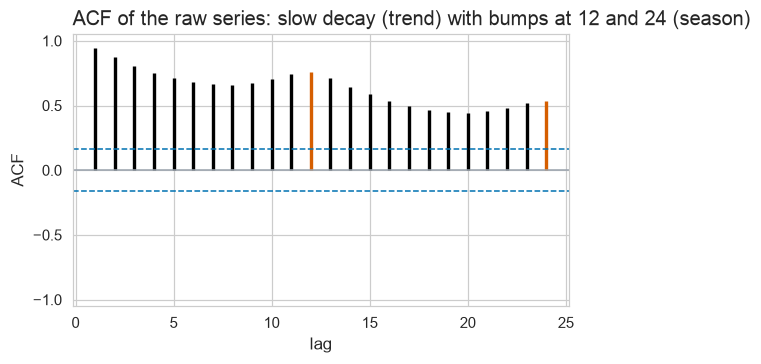

ACF lag 1 = 0.95   lag 6 = 0.68   lag 12 = 0.76   lag 24 = 0.53


In [7]:
ax = P.acf_plot(df["y"].to_numpy(), nlags=24, highlight_every=SEASON_LENGTH,
                title="ACF of the raw series: slow decay (trend) with bumps at 12 and 24 (season)")
plt.savefig("figures/03_acf.png", bbox_inches="tight")
plt.show()

from statsmodels.tsa.stattools import acf
r = acf(df["y"], nlags=24)
print(f"ACF lag 1 = {r[1]:.2f}   lag 6 = {r[6]:.2f}   lag 12 = {r[12]:.2f}   lag 24 = {r[24]:.2f}")

**What the ACF says.** Every lag is strongly positive and the bars shrink
only slowly: that slow decay is the **trend** (this month looks like last
month mostly because both are high). On top of it there are local peaks at
**lag 12 and lag 24**, higher than the lags around them: the same month one
and two years ago is unusually similar to this month. That is the **yearly
season**, and it is the reason the floor below copies "same month last year".

*In one sentence a non-forecaster could repeat:* "The number keeps going up,
and every month looks a lot like the same month a year earlier."

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, RandomWalkWithDrift, SeasonalNaive

# The floor (seasonal naive) plus two more benchmarks: naive and naive with drift.
floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH),
                                 Naive(), RandomWalkWithDrift()],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,...,RWD-lo-20,RWD-lo-40,RWD-lo-60,RWD-lo-80,RWD-lo-95,RWD-hi-20,RWD-hi-40,RWD-hi-60,RWD-hi-80,RWD-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,...,425.686422,416.537433,405.830137,390.980968,368.082204,442.789103,451.938092,462.645388,477.494557,500.393321
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,...,424.340185,411.356712,396.161822,375.089135,342.593144,448.610864,461.594337,476.789227,497.861914,530.357905
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,...,423.799429,407.843249,389.169324,363.271816,323.335514,453.627145,469.583325,488.257250,514.154757,554.091059
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,...,423.671134,405.183533,383.547023,353.540922,307.268796,458.230964,476.718564,498.355075,528.361176,574.633302
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,...,423.803677,403.063726,378.791231,345.129475,293.219998,462.573945,483.313897,507.586391,541.248147,593.157624


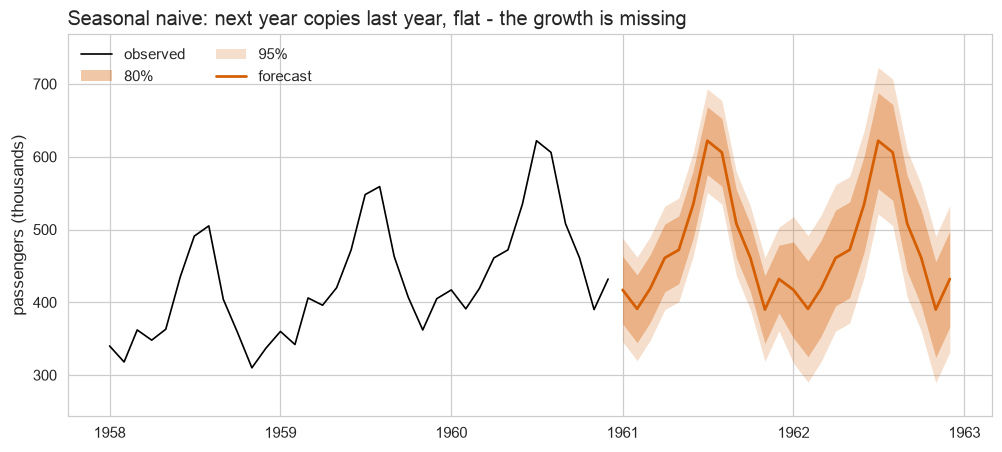

In [9]:
def as_fan(fc, model):
    """One model's columns renamed to the mean / lo-L / hi-L shape fan_chart reads."""
    out = fc[["ds", model]].rename(columns={model: "mean"})
    for lvl in scoring.LEVELS:
        out[f"lo-{lvl}"] = fc[f"{model}-lo-{lvl}"]
        out[f"hi-{lvl}"] = fc[f"{model}-hi-{lvl}"]
    return out

P.fan_chart(df, as_fan(floor_fc, "SeasonalNaive"),
            title="Seasonal naive: next year copies last year, flat - the growth is missing",
            history_tail=36, levels=(80, 95))
plt.gca().set_ylabel("passengers (thousands)")
plt.show()

The floor repeats 1960 for 1961 and again for 1962. It has the right *shape*
but no growth, so on a series that grew every single year it will be too low,
and its band (built from last year's changes) does not widen for the higher
level either.

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

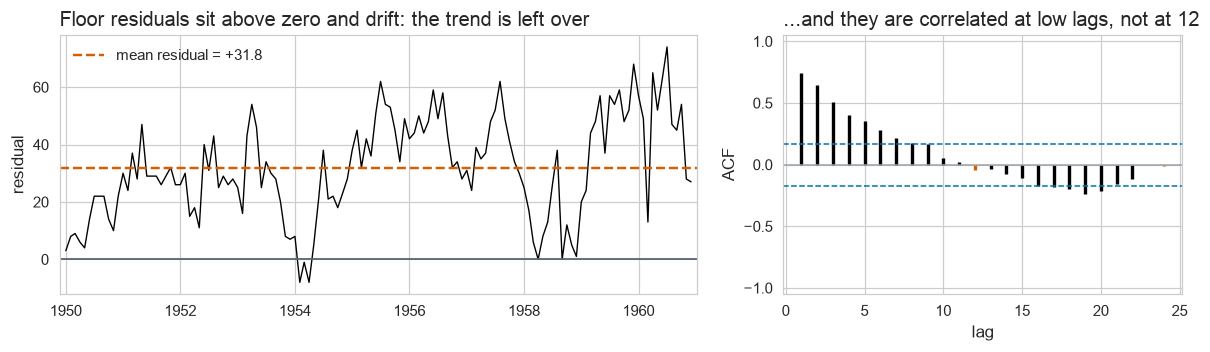

mean residual = 31.8k (should be ~0)
residual ACF: lag 1 = 0.75, lag 2 = 0.65, lag 3 = 0.50, lag 12 = -0.04


In [10]:
# The floor's in-sample residuals: y_t - y_{t-12}. The first 12 months have no residual.
resid_floor = (df["y"] - df["y"].shift(SEASON_LENGTH)).dropna()
ds_floor = df["ds"].iloc[SEASON_LENGTH:]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1.6, 1]})
P.residual_time_plot(resid_floor.to_numpy(), ds=ds_floor, ax=axes[0], show_mean=True,
                     title="Floor residuals sit above zero and drift: the trend is left over")
P.acf_plot(resid_floor.to_numpy(), nlags=24, ax=axes[1], highlight_every=SEASON_LENGTH,
           title="...and they are correlated at low lags, not at 12")
plt.tight_layout()
plt.savefig("figures/04_floor_residuals.png", bbox_inches="tight")
plt.show()

ra = acf(resid_floor, nlags=24)
print(f"mean residual = {resid_floor.mean():.1f}k (should be ~0)")
print(f"residual ACF: lag 1 = {ra[1]:.2f}, lag 2 = {ra[2]:.2f}, lag 3 = {ra[3]:.2f}, lag 12 = {ra[12]:.2f}")

**What the floor leaves on the table.**

- **Trend, yes.** The residuals average about **+32 thousand**, not zero:
  every year is higher than the year before, and "same month last year" never
  catches up. The residuals also wander in long runs above and below their mean.
- **Low-lag autocorrelation, yes.** The ACF is large at lags 1-3 (about
  0.75, 0.65, 0.50) and decays slowly: a good year is followed by another good
  year. Errors that predict the next error are information the floor throws away.
- **Lag 12, no.** The residual ACF at 12 is about zero, so the season itself
  has been fully used; differencing by 12 already did its job.

**Which model eats it:** the leftover is a trend plus autocorrelated
year-on-year growth. That is what a **seasonal ARIMA with a regular difference
and an AR term** absorbs (and what ETS does with a trend/level state). The
seasonal part needs no more help.

**2.2 An honest interval for the floor.** The seasonal naive's band says
"80% of the time the truth lands inside". That is a claim; coverage checks
it. The check has to come out of the rolling-origin harness (eight 12-month
origins, the same folds section 4 uses), not from the fit itself.

In [11]:
floor_cv = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1).cross_validation(
    df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)
floor_cov = scoring.coverage(floor_cv, "SeasonalNaive", level=80)
floor_w80 = (floor_cv["SeasonalNaive-hi-80"] - floor_cv["SeasonalNaive-lo-80"]).mean()
print(f"floor 80% band: average width {floor_w80:.0f}k passengers")
print(f"floor 80% coverage over 8 folds x 12 months: {floor_cov:.0%}  (nominal 80%)")

floor 80% band: average width 78k passengers
floor 80% coverage over 8 folds x 12 months: 51%  (nominal 80%)


**Verdict on the floor's band: not honest.** It claims 80% and covers only
about **51%** of the 96 months it was tested on. The band is built as if next
year's error were as random as past year-on-year changes, but the error is
mostly the *missing trend*, which is systematic: the truth lands above the
band again and again. A band this short is worse than useless for planning,
because it looks precise.

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [12]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG and "google.colab" in sys.modules:
    print("Installing autogluon.timeseries (a few minutes on Colab)...")
    !pip install -q "autogluon.timeseries"
    importlib.invalidate_caches()
    HAS_AG = importlib.util.find_spec("autogluon") is not None

if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [13]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # The conversion, by hand: AutoGluon wants item_id / timestamp / <target>,
    # one row per (series, time step), indexed by both. Same data, new names.
    ag_long = pd.DataFrame({
        "item_id": df["unique_id"],          # unique_id -> item_id
        "timestamp": df["ds"],               # ds        -> timestamp
        "y": df["y"],                        # y stays, declared as target= below
    })
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects: train stops 12 steps early.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows ({tsdf.index.get_level_values('timestamp').min().date()} to "
          f"{tsdf.index.get_level_values('timestamp').max().date()})   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows (1949-01-01 to 1960-12-01)   train: 132 rows


In [14]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1, path="AutogluonModels/airpassengers")
    # num_val_windows=1 is AutoGluon's default, written out so the reader sees it:
    # the internal ranking (score_val) is scored on ONE 12-month window.
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120, num_val_windows=1)

In [15]:
if HAS_AG:
    # score_test: each model refit-free forecast of the held-out 12 months (1960) vs truth.
    # score_val : AutoGluon's own internal validation, the last 12 months of ag_train (1959).
    lb = predictor.leaderboard(tsdf)
    display(lb[["model", "score_test", "score_val", "fit_order"]])

,model,score_test,score_val,fit_order
0,AutoARIMA,-0.608073,-1.575987,5
1,Theta,-0.875371,-1.633923,3
2,WeightedEnsemble,-0.929514,-1.535792,6
3,AutoETS,-1.169539,-1.554323,4
4,SeasonalNaive,-1.570881,-1.656513,2
5,Naive,-2.495895,-3.196371,1


**3.2 Reading the leaderboard.**

- **The sign.** Both `score_test` and `score_val` are **negative**. AutoGluon
  always sorts "higher is better", so it reports error metrics with the sign
  flipped: `score_val = -1.58` means a MASE of 1.58. Closer to zero is better.
- **What it fitted.** Five local models from the zoo (Naive, SeasonalNaive,
  AutoETS, AutoARIMA, Theta) plus a **WeightedEnsemble** it built from them.
- **How many windows.** `score_val` comes from **one** internal window (the
  last 12 months of the training data, 1959), and `score_test` from **one**
  more (the 12 held-out months, 1960). Two single-window rankings, and they
  **disagree**: on 1959 the ensemble and AutoETS look best; on 1960 AutoARIMA
  is clearly first and AutoETS falls behind Theta.

**What this ranking can and cannot be trusted to do:** it can *shortlist*
(every model with a trend and a season beats both naives on both windows, so
the floor is clearly beatable), but it cannot *rank* the shortlist, because
one window is twelve correlated months from one year and the order already
flips between two neighbouring years. That is why the shortlist (AutoARIMA,
AutoETS, Theta) goes to the harness next.

**Does it agree with section 1?** Yes: the winners are exactly the models that
carry both a trend and a season, which is what the trend and seasonal strengths
(both ~1) said was needed; the two naives, which each drop one of them, are
at the bottom.

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [16]:
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta

# The shortlist, through statsforecast (the framework twins of AutoGluon's
# AutoARIMA / AutoETS / Theta), on the SAME eight origins as the floor:
# h = 12, step = 12, 8 windows -> cutoffs Dec-1952 ... Dec-1959.
MODELS = [SeasonalNaive(season_length=SEASON_LENGTH), Naive(), RandomWalkWithDrift(),
          AutoETS(season_length=SEASON_LENGTH), AutoTheta(season_length=SEASON_LENGTH),
          AutoARIMA(season_length=SEASON_LENGTH)]
NAMES = ["SeasonalNaive", "Naive", "RWD", "AutoETS", "AutoTheta", "AutoARIMA"]

sf_cv = StatsForecast(models=MODELS, freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)
print("cutoffs:", [c.strftime("%Y-%m") for c in sorted(cv["cutoff"].unique())])
print(f"{cv['cutoff'].nunique()} folds x {H} months = {len(cv)} scored months per model")
cv.head()

cutoffs: ['1952-12', '1953-12', '1954-12', '1955-12', '1956-12', '1957-12', '1958-12', '1959-12']
8 folds x 12 months = 96 scored months per model


,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,...,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-lo-60,AutoARIMA-lo-40,AutoARIMA-lo-20,AutoARIMA-hi-20,AutoARIMA-hi-40,AutoARIMA-hi-60,AutoARIMA-hi-80,AutoARIMA-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,...,186.129326,190.942209,194.063221,196.313689,198.236632,201.831289,203.754231,206.004700,209.125712,213.938594
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,...,191.099431,196.240171,199.573789,201.977561,204.031496,207.871024,209.924959,212.328732,215.662349,220.803089
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,...,210.220348,216.545092,220.646501,223.603905,226.130899,230.854738,233.381731,236.339135,240.440545,246.765289
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,...,194.752951,201.558047,205.970950,209.152963,211.871877,216.954482,219.673395,222.855409,227.268312,234.073408
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,...,199.055069,206.593888,211.482588,215.007685,218.019750,223.650360,226.662425,230.187522,235.076222,242.615041


In [17]:
MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)   # the leaderboard's test winner
MY_NAME = "AutoARIMA"

# The floor and the shortlisted model were fitted above in ONE cross_validation
# call, so they share exactly the same folds. score_cv scores each fold's MASE
# and RMSSE against that fold's own history only (no leakage in the denominator).
rows = {}
for name in NAMES:
    s = scoring.score_cv(cv, name, df)
    s["width_80"] = float((cv[f"{name}-hi-80"] - cv[f"{name}-lo-80"]).mean())
    rows[name] = s

RESULTS = (pd.DataFrame(rows).T[["mase", "rmsse", "crps", "coverage_80",
                                 "mase_min", "mase_max", "width_80"]]
           .sort_values("crps"))
RESULTS.round(3)

,mase,rmsse,crps,coverage_80,mase_min,mase_max,width_80
AutoARIMA,0.647,0.683,0.034,0.698,0.330,1.594,44.076
AutoTheta,0.898,0.988,0.046,0.594,0.451,1.405,58.212
AutoETS,0.952,1.003,0.050,0.490,0.565,1.554,48.721
SeasonalNaive,1.313,1.246,0.062,0.510,0.412,1.959,77.758
RWD,1.813,2.156,0.095,0.760,1.187,2.766,148.523
Naive,2.119,2.452,0.110,0.688,1.422,3.196,142.947


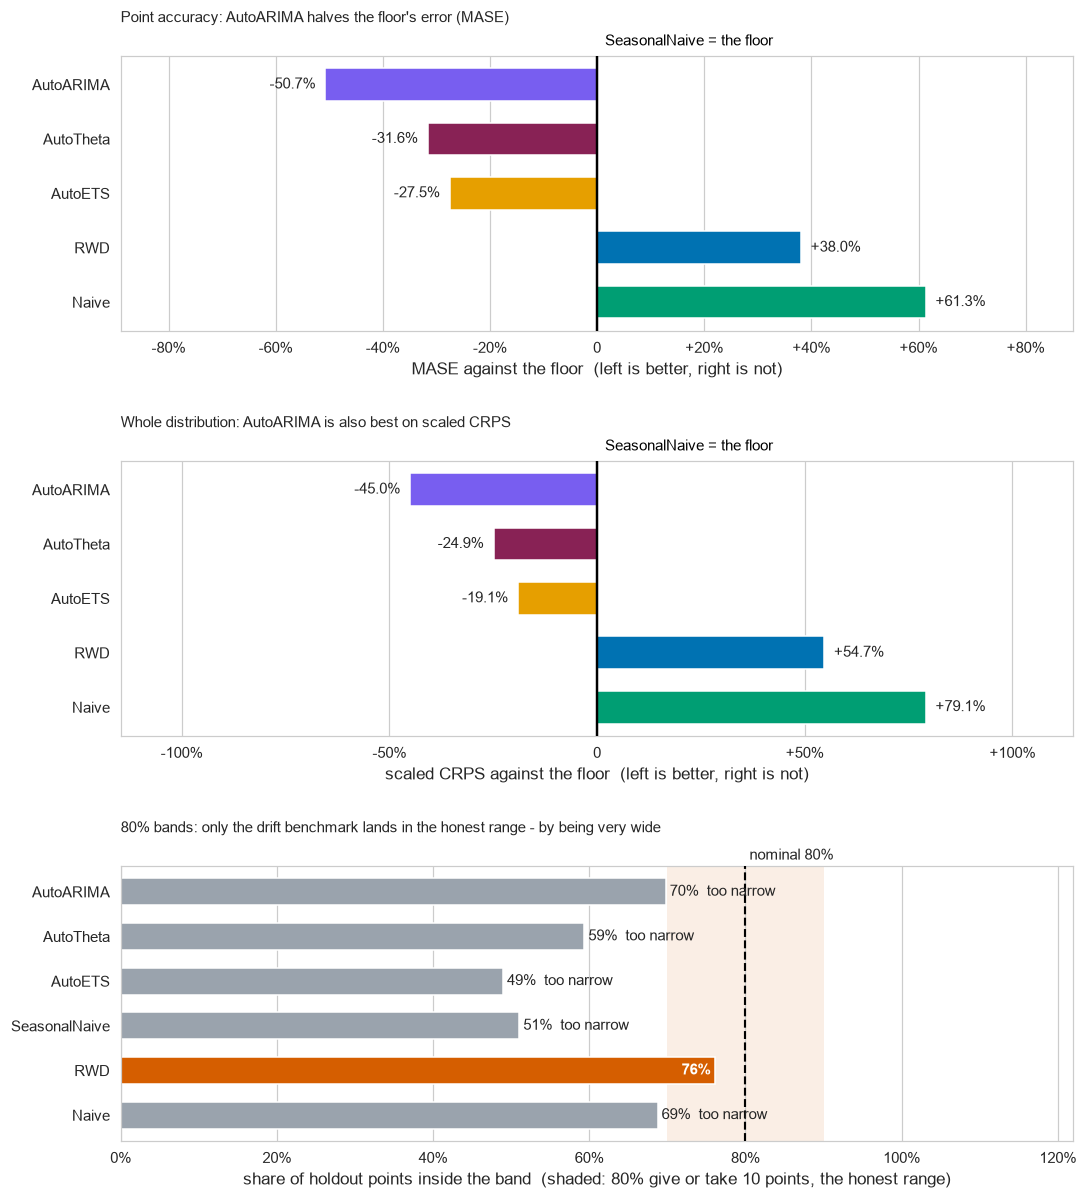

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(10, 11))
P.metric_vs_baseline_plot(RESULTS["mase"].to_dict(), "SeasonalNaive", ax=axes[0],
                          metric="MASE", title="")
P.metric_vs_baseline_plot(RESULTS["crps"].to_dict(), "SeasonalNaive", ax=axes[1],
                          metric="scaled CRPS", title="")
P.coverage_bars(RESULTS["coverage_80"].to_dict(), nominal=0.8, ax=axes[2], title="")
for ax, claim in zip(axes, [
        "Point accuracy: AutoARIMA halves the floor's error (MASE)",
        "Whole distribution: AutoARIMA is also best on scaled CRPS",
        "80% bands: only the drift benchmark lands in the honest range - by being very wide"]):
    ax.set_title(claim, loc="left", size="medium", pad=22)
plt.tight_layout(h_pad=2.5)
plt.savefig("figures/05_harness.png", bbox_inches="tight")
plt.show()

In [19]:
# Where the winner wins and loses: fold by fold, against the floor.
def fold_table(model):
    out = []
    for cut, g in cv.groupby("cutoff"):
        hist = df[df["ds"] <= cut]
        sc = scoring.score_cv(g, model, hist)
        out.append({"forecast year": cut.year + 1, "MASE": sc["mase"],
                    "coverage_80": sc["coverage_80"]})
    return pd.DataFrame(out).set_index("forecast year")

folds = fold_table("SeasonalNaive").join(fold_table(MY_NAME), lsuffix=" floor",
                                          rsuffix=f" {MY_NAME}")
folds["ARIMA beats floor"] = folds[f"MASE {MY_NAME}"] < folds["MASE floor"]
folds.round(2)

,MASE floor,coverage_80 floor,MASE AutoARIMA,coverage_80 AutoARIMA,ARIMA beats floor
forecast year,,,,,
1953,1.19,0.67,0.44,0.75,True
1954,0.68,0.92,0.39,0.83,True
1955,1.96,0.08,0.77,0.50,True
1956,1.66,0.25,0.33,1.00,True
1957,1.38,0.67,0.41,0.92,True
1958,0.41,1.00,0.64,0.75,False
1959,1.66,0.25,1.59,0.00,True
1960,1.57,0.25,0.61,0.83,True


**4.1 Reading the table.**

- **The harness confirms the shortlist and settles its order.** Over eight
  years, **AutoARIMA** has the lowest MASE (**0.65** vs the floor's 1.31, about
  half the error) *and* the lowest scaled CRPS (**0.034** vs 0.062, about 45%
  better), so it wins the point forecast and the whole distribution. AutoTheta
  and AutoETS also beat the floor on both, by less. The two non-seasonal
  benchmarks (Naive, drift) lose to the floor on everything: the season is
  the first thing a model must have.
- **Where it loses.** AutoARIMA beats the floor in **7 of the 8** forecast
  years. It loses in **1958**, the one year that almost repeated the year
  before (growth stalled), so copying last year was nearly perfect (floor MASE
  0.41 vs 0.64). Its worst year is **1959** (MASE 1.59, still just ahead of the
  floor's 1.66), when growth jumped and the whole year landed above its band.
  The average win is real, but it hides year-to-year risk.
- **A win on the point, a loss on the band.** AutoETS beats the floor on MASE
  (0.95 vs 1.31) and on CRPS, yet its 80% band covers *less* than the floor's
  (49% vs 51%). Both halves are the result.
- **Coverage verdict.** Reading coverage against the honest range (80% give or
  take 10 points), **only one band is honest, and it belongs to the wrong
  model**: the drift benchmark covers 76%, but only because its band is more
  than three times wider than AutoARIMA's while its forecasts are among the
  worst. Every useful model is too narrow: AutoARIMA covers **70%** (just
  outside the range, 10 points short), AutoTheta 59%, the floor 51%, AutoETS
  49%. The misses come **a whole year at a
  time** (AutoARIMA covered 50% in 1955 and 0% in 1959): in years when growth
  jumps, the truth sits above the band for twelve months straight, which a band
  built for random, independent errors cannot anticipate.

---
# 4b. The model I would ship: forecast and residuals

The harness picks AutoARIMA. Refit it on all 144 months for the 24-month
forecast the report quotes, and read its residuals: what is still left.

selected: ARIMA(1,1,0)(0,1,0)[12]


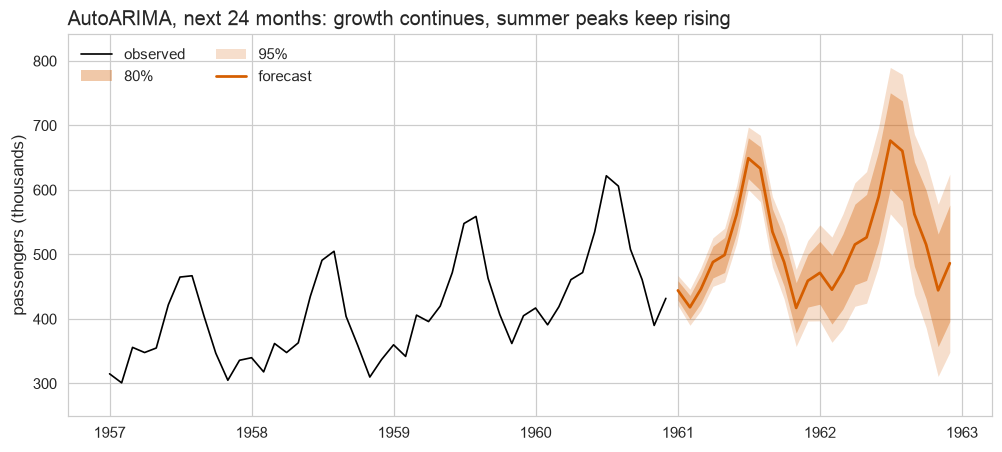

1961 forecast total: 6,041k passengers (1960 actual: 5,714k)
80% band width: 30k at month 1, 82k at month 12, 181k at month 24


In [20]:
final_sf = StatsForecast(models=[AutoARIMA(season_length=SEASON_LENGTH)], freq="MS", n_jobs=1)
final_sf.fit(df=df)                                   # fit once on all 144 months...
final_fc = final_sf.predict(h=H_REPORT, level=scoring.LEVELS)   # ...then forecast 24 ahead
arima = final_sf.fitted_[0, 0].model_
p, q, P_, Q_, m, d, D = arima["arma"]
print(f"selected: ARIMA({p},{d},{q})({P_},{D},{Q_})[{m}]")

P.fan_chart(df, as_fan(final_fc, "AutoARIMA"), history_tail=48, levels=(80, 95),
            title="AutoARIMA, next 24 months: growth continues, summer peaks keep rising")
plt.gca().set_ylabel("passengers (thousands)")
plt.savefig("figures/06_forecast.png", bbox_inches="tight")
plt.show()

w80 = (final_fc["AutoARIMA-hi-80"] - final_fc["AutoARIMA-lo-80"])
print(f"1961 forecast total: {final_fc['AutoARIMA'].iloc[:12].sum():,.0f}k passengers "
      f"(1960 actual: {df['y'].iloc[-12:].sum():,.0f}k)")
print(f"80% band width: {w80.iloc[0]:.0f}k at month 1, {w80.iloc[11]:.0f}k at month 12, {w80.iloc[23]:.0f}k at month 24")

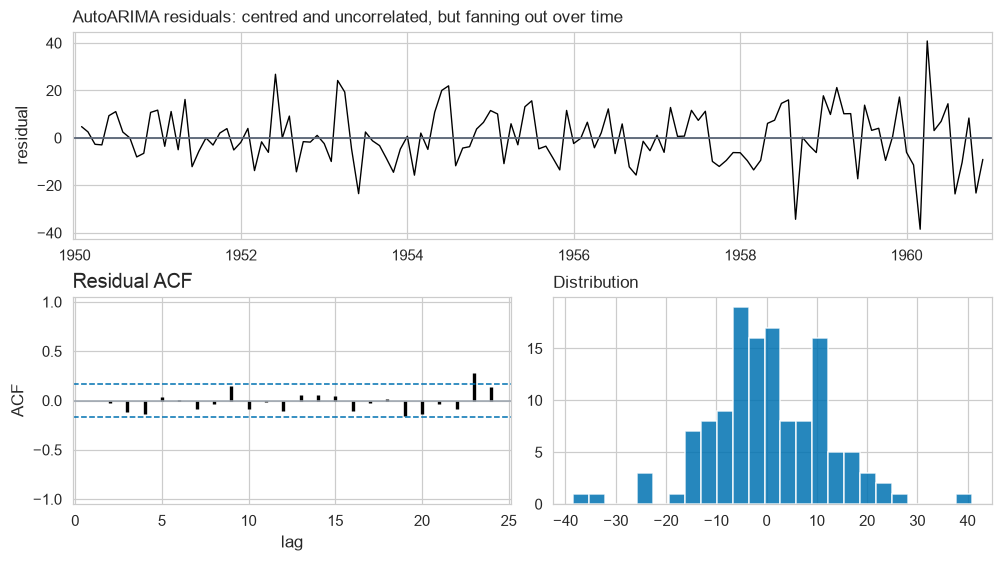

mean residual: 0.24k
largest |ACF| over lags 1-24: 0.28  (significance band +/- 0.17)
residual std: first 4 years 9.8k, last 4 years 14.6k  (x1.5)


In [21]:
# In-sample one-step residuals of the fitted model; drop the differencing burn-in (d + D*12 months).
resid_arima = pd.Series(arima["residuals"]).iloc[SEASON_LENGTH + 1:].reset_index(drop=True)
ds_arima = df["ds"].iloc[SEASON_LENGTH + 1:].reset_index(drop=True)

fig, axes = P.residual_diagnostics(resid_arima.to_numpy(), ds=ds_arima, nlags=24,
                                   title="AutoARIMA residuals: centred and uncorrelated, but fanning out over time")
plt.savefig("figures/07_arima_residuals.png", bbox_inches="tight")
plt.show()

ra2 = acf(resid_arima, nlags=24)
early, late = resid_arima.iloc[:48].std(), resid_arima.iloc[-48:].std()
print(f"mean residual: {resid_arima.mean():.2f}k")
print(f"largest |ACF| over lags 1-24: {np.abs(ra2[1:]).max():.2f}  (significance band +/- {1.96/np.sqrt(len(resid_arima)):.2f})")
print(f"residual std: first 4 years {early:.1f}k, last 4 years {late:.1f}k  (x{late/early:.1f})")

**What the model missed.** Compared with the floor's residuals, the
structure is gone: the residuals are centred on zero (mean 0.2k) and the ACF
has nothing at the lags that matter (1-3, 12, 24), so the trend and the
autocorrelation the floor left behind have been absorbed. One bar crosses the
significance band, at **lag 23** (0.28); with 24 bars tested at 5%, about one
false alarm is expected by chance, and a 23-month echo has no plausible
business meaning, so I read it as noise. What is left is
**heteroscedasticity**: the residuals are about **1.5 times** as spread out in
the last four years as in the first four. The model is fitted on raw passenger counts, so it assumes one
error size for 1950 and 1960 alike. That is exactly why its 80% band
under-covers in the busier later years. **The model is missing a scale for
its errors that grows with the level** - a log (or Box-Cox) transform before
fitting would give it one.

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

The report is written up in [`report.md`](report.md); every number in it is
printed above. The charts it uses are saved to `figures/` by the cells above.

---
# 6. Extra credit: dynamic regression on a sourced driver

**The driver.** The series is a total, so a driver is a modelling choice. I
use **monthly mean temperature at New York (Idlewild / JFK)**, the busiest
international gateway of the period, from the Open-Meteo historical archive
(ERA5 reanalysis, free, no key). It is fetched once and **cached** as
`data/temperature_nyc_monthly.csv`, so the notebook does not depend on the API.

**The model.** AutoARIMA with temperature as a regressor: a regression on
temperature with ARIMA errors.

**The discipline.** Future temperature is not known when a forecast is made,
so feeding the fold its *actual* future temperatures would be leakage. Each
fold instead uses the **monthly climatology computed from that fold's own
training years** as its future regressor, and the fit, the climatology and
the MASE denominator all see only data up to the cutoff. Same eight origins,
same scoring.

In [22]:
import pathlib
import urllib.request, json

TEMP_CSV = pathlib.Path("data/temperature_nyc_monthly.csv")
if not TEMP_CSV.exists():
    url = ("https://archive-api.open-meteo.com/v1/archive?latitude=40.64&longitude=-73.78"
           "&start_date=1949-01-01&end_date=1960-12-31&daily=temperature_2m_mean&timezone=UTC")
    daily = json.load(urllib.request.urlopen(url, timeout=60))["daily"]
    daily = pd.DataFrame({"ds": pd.to_datetime(daily["time"]), "temp": daily["temperature_2m_mean"]})
    TEMP_CSV.parent.mkdir(exist_ok=True)
    daily.set_index("ds").resample("MS").mean().round(2).reset_index().to_csv(TEMP_CSV, index=False)

temp = pd.read_csv(TEMP_CSV, parse_dates=["ds"])
data = df.merge(temp, on="ds", how="left")
assert data["temp"].notna().all() and len(data) == len(df)
print(f"cached driver: {len(temp)} months, {temp['ds'].min().date()} to {temp['ds'].max().date()}")
print(f"correlation with passengers: {data['temp'].corr(data['y']):.2f} (mostly the shared season)")

cached driver: 144 months, 1949-01-01 to 1960-12-01
correlation with passengers: 0.24 (mostly the shared season)


In [23]:
cutoffs = sorted(cv["cutoff"].unique())     # the SAME eight origins as section 4

def rolling_regression(with_temp):
    folds = []
    for cut in cutoffs:
        train = data[data["ds"] <= cut]
        test = data[data["ds"] > cut].head(H)
        # Climatology from the fold's history only - the honest "known future" value.
        clim = train.groupby(train["ds"].dt.month)["temp"].mean()
        X_future = test[["unique_id", "ds"]].assign(temp=test["ds"].dt.month.map(clim).to_numpy())
        cols = ["unique_id", "ds", "y"] + (["temp"] if with_temp else [])
        sf = StatsForecast(models=[AutoARIMA(season_length=SEASON_LENGTH, alias="M")],
                           freq="MS", n_jobs=1)
        fc = sf.forecast(df=train[cols], h=H, X_df=X_future if with_temp else None,
                         level=scoring.LEVELS)
        folds.append(fc.assign(cutoff=cut).merge(test[["ds", "y"]], on="ds"))
    return pd.concat(folds, ignore_index=True)

reg_rows = {}
for label, flag in [("AutoARIMA (harness)", None), ("AutoARIMA, no driver (loop)", False),
                    ("AutoARIMA + temperature", True)]:
    if flag is None:
        reg_rows[label] = scoring.score_cv(cv, "AutoARIMA", df)
    else:
        reg_rows[label] = scoring.score_cv(rolling_regression(flag), "M", df)
pd.DataFrame(reg_rows).T[["mase", "rmsse", "crps", "coverage_80", "mase_max"]].round(3)

,mase,rmsse,crps,coverage_80,mase_max
AutoARIMA (harness),0.647,0.683,0.034,0.698,1.594
"AutoARIMA, no driver (loop)",0.647,0.683,0.034,0.698,1.594
AutoARIMA + temperature,0.665,0.692,0.034,0.708,1.587


ARIMA errors: (1, 0, 0, 0, 12, 1, 1)   coefficient on temperature (ex_1): +0.80k passengers per degree C


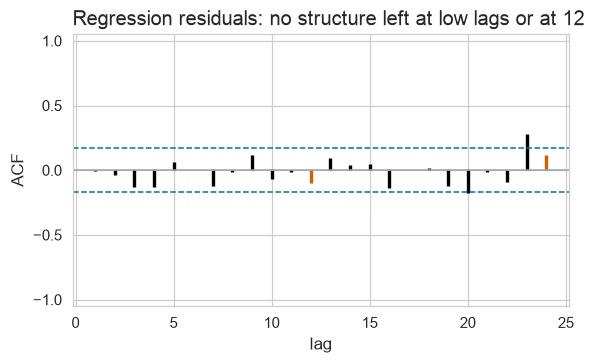

In [24]:
# Residual check on the regression itself (fitted on all 144 months, actual temperatures).
reg_sf = StatsForecast(models=[AutoARIMA(season_length=SEASON_LENGTH, alias="M")], freq="MS", n_jobs=1)
reg_sf.fit(data[["unique_id", "ds", "y", "temp"]])
reg_model = reg_sf.fitted_[0, 0].model_
coef = reg_model["coef"]
# statsforecast names the first exogenous column "ex_1" (here: temp).
print(f"ARIMA errors: {reg_model['arma']}   coefficient on temperature (ex_1): "
      f"{float(coef['ex_1']):+.2f}k passengers per degree C")
reg_resid = pd.Series(reg_model["residuals"]).iloc[SEASON_LENGTH + 1:]
P.acf_plot(reg_resid.to_numpy(), nlags=24, highlight_every=SEASON_LENGTH,
           title="Regression residuals: no structure left at low lags or at 12")
plt.show()

**Verdict on the driver.** The loop reproduces the harness AutoARIMA exactly
(same MASE), which confirms the hand-rolled folds are the same folds. Adding
temperature does **not** help: MASE gets slightly worse (0.665 vs 0.647), CRPS
is unchanged, coverage moves by about one point. The fitted coefficient is
about **+0.8 thousand passengers per extra degree**, small next to monthly swings
of 200 thousand. Temperature is almost entirely
a *seasonal* signal, and seasonal differencing already removes the season, so
after differencing the driver has little left to explain; its residuals look
like the ARIMA's. That is a result, not a failure: **a driver earns its place
only if it carries information the season does not**, which points to drivers
like fares, income or route capacity rather than weather.